# 00 · Questions, outcomes and data

This notebook states the six questions *before* any result. Notebooks 01–03 answer them in a fixed
order — **easy synthetic → harder synthetic → real data** — and each section ends with an
*Observed outcome* line chosen by a rule written in code here, not by reading the plot.

**The setting in one line.** One set of factor scores $Z$ ($N\times K$) drives every view:
$Y^{(m)}\approx Z\,W^{(m)\top}$. Factor $k$ is **shared** if its loading column $W^{(m)}_{\cdot k}$ is non-zero in
every view, **private** to view $m$ if only there. The *pattern* of factor $k$ is the 0/1 vector
$H_{\cdot k}$ over views. "Shared" in these notebooks always means *shared between views*, never
between cohorts.

**Development note (honesty).** Before these notebooks were written, a pilot on easy data showed
that (a) a learned cohort $\pi$ drifts towards 1 and (b) a cold-started view switch stays on.
Both observations shaped two *extra* arms — the paired cohort factorisation (Q1) and the warm-started
switch (Q4) — but the original arms are kept and the outcomes below were fixed before the runs
reported in notebooks 01–03.

In [1]:
import os, sys, warnings
os.environ["TQDM_DISABLE"] = "1"
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks_sharedness" else os.getcwd()
sys.path.insert(0, ROOT)
os.chdir(ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
from sharedness import experiments as ex, metrics as mt
from sharedness.data import make_view_data, H_EASY, pattern_for

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook")
RESULTS = os.path.join(ROOT, "notebooks_sharedness", "results")
os.makedirs(RESULTS, exist_ok=True)

def outcome(code_text, title="Observed outcome"):
    code, text = code_text
    display(Markdown(f"> **{title}: {code}** — {text}"))
    return code

## Q1 — Can CohortFACTM learn how often cohorts differ?

**In plain words.** CohortFACTM gives every (cohort, factor) pair a switch $\gamma_{ck}$: *does cohort $c$ have its
own centre on factor $k$?* Today the switch rate $\pi$ is a number we pick (0.5). If we let the model
**learn** $\pi$, does it find the true rate?

**Precisely.**
$$z_{nk}\mid c \sim \mathcal N(\gamma_{ck}\delta_{ck},\ \tau_{ck}^{-1}),\qquad
\gamma_{ck}\sim\mathrm{Bern}(\pi),\qquad \pi\sim\mathrm{Beta}(1,1).$$
Mean-field update: $q(\pi)=\mathrm{Beta}\big(1+\sum_{c,k}\mathbb E[\gamma_{ck}],\ 1+CK-\sum_{c,k}\mathbb E[\gamma_{ck}]\big)$.

**Data:** cohort switches drawn with rate $\pi^\ast\in\{0.1,0.3,0.6\}$ ($C=6$, shift $\pm2$).
Because the data are centred globally, the switch can only see a cohort's mean *relative to the grand
mean*; the truth we score against is $G^{\text{eff}}_{ck}=\mathbb 1\{|\bar z_{ck}-\bar z_{\cdot k}|>1\}$.

**Measured:** $\mathbb E[\pi\mid Y]$ against the effective true rate, and the AUC of $\mathbb E[\gamma]$ against $G^{\text{eff}}$.

**Arms:** (i) fixed $\pi=0.5$ (current model); (ii) learned $\pi$ with the current factorisation
$q(\gamma)q(\delta)$; (iii) learned $\pi$ with the paired factorisation $q(\gamma)q(\delta\mid\gamma)$.

**Possible outcomes (fixed before running; thresholds live in `sharedness/experiments.py`).**

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O1** | Learnable | max $|\mathbb E[\pi]-\pi^\ast| < 0.15$ and slope $>0.5$ | the data carry the rate; keep $\pi$ learnable |
| **O2** | Drifts to 1 | $\mathbb E[\pi] > 0.8$ at every $\pi^\ast$ | switches are never pushed off; the factorisation, not the formula, is at fault |
| **O3** | Prior-dominated | $\mathbb E[\pi]$ moves $<0.2$ across $\pi^\ast$ | too few switches ($CK$) to learn from; fix $\pi$ |
| **O4** | Partial | anything else | moves with the truth but biased; report the bias |

## Q2 — Can a plain fit, with no new parts, already show which factors are shared?

**In plain words.** Fit the model we already have. For each factor, ask each view *how much of you does this factor
explain?* If the answer is ~0 in some views and large in others, the fit has told us the pattern
for free.

**Precisely.**
Variance share of factor $k$ in view $m$ (non-negative, unlike `FA.variance_explained_per_factor_view`):
$$r_{mk}=\frac{\lVert \mathbb E[z_{\cdot k}]\,\mathbb E[w^{(m)}_{\cdot k}]^{\top}\rVert_F^2}{\lVert Y^{(m)}\rVert_F^2},
\qquad a_{mk}=\frac{r_{mk}}{\max_{m'} r_{m'k}}\in[0,1].$$
Sharedness of factor $k$: $S_k=-\sum_m p_{mk}\log p_{mk}/\log M$, $p_{mk}=r_{mk}/\sum_{m'}r_{m'k}$
($1$ = spread over all views, $0$ = one view).

**Measured:** after matching fitted to true factors (Hungarian on $|\mathrm{corr}|$),
$\mathrm{AUC}(a, H)=P(a_{mk}>a_{m'k'}\mid H_{mk}=1,H_{m'k'}=0)$ — threshold-free, $1$ perfect, $0.5$ chance.

**Arms:** no loadings prior ($w\sim\mathcal N(0,1)$) and ARD.

**Possible outcomes (fixed before running; thresholds live in `sharedness/experiments.py`).**

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O1** | Yes, any fit | AUC $\ge 0.95$ with and without ARD | sharedness is a read-out; no new model needed to *see* it |
| **O2** | Yes, with ARD | AUC $\ge 0.95$ only with ARD | ARD is what makes it readable |
| **O3** | Partly | best AUC in $[0.75, 0.95)$ | some cells wrong; inspect leaks |
| **O4** | No | best AUC $<0.75$ | the fit does not expose the pattern |

## Q2b — When the fit misses the true factors, is it the optimiser or the model?

**In plain words.** Reading the pattern needs the right factors first. If a fit lands on a *rotated* set of factors,
there are two very different explanations: the model would prefer the truth but the algorithm never
gets there (an **optimiser** problem — fixable), or the model's own objective prefers the rotated
answer (a **model / identification** problem — needs theory).

**Precisely.**
For every seed where the ARD fit from the usual PCA start has $\min_k|\mathrm{corr}(\hat z_k,z^\ast_k)|<0.9$,
refit starting **at the truth** $(Z^\ast,W^\ast)$ and compare
$$\Delta_{\text{start}}=\mathrm{ELBO}_{\text{truth start}}-\mathrm{ELBO}_{\text{PCA start}}.$$

**Possible outcomes (fixed before running; thresholds live in `sharedness/experiments.py`).**

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O0** | Not needed | every fit found the true axes | skip |
| **O1** | Optimiser | $\Delta_{\text{start}}>10$ nats and the truth start keeps the true axes | better initialisation or annealing would fix it |
| **O2** | Model | $\Delta_{\text{start}}<-10$ or the truth start drifts away | the ELBO prefers a rotation: an identification result to prove (Lemma C regime) |
| **O3** | Flat | $|\Delta_{\text{start}}|\le10$ | the rotation is (nearly) unidentified |

## Q3 — How many views do we need before ‘shared vs private’ is a meaningful question?

**In plain words.** With 2 views there are only 3 patterns: shared, private to view 1, private to view 2. With 4 views
there are 15. Does having few views make the pattern harder to *detect*, or just coarser?

**Precisely.**
Number of non-empty patterns: $2^M-1$. A per-factor rate learned from $M$ switches has posterior
$\mathrm{Beta}(1+s_k,\,1+M-s_k)$ with $s_k=\sum_m h_{mk}$ — so even a *perfectly* observed pattern
leaves $\mathrm{sd}(\pi_k)$ large when $M$ is small (table below, no fitting needed).

**Data:** one shared factor, one factor in views 1–2 (if $M>2$), one private factor per view;
$M\in\{2,3,4,6\}$. **Measured:** AUC of ARD activity against $H$.

**Possible outcomes (fixed before running; thresholds live in `sharedness/experiments.py`).**

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O1** | M does not limit detection | AUC $\ge0.95$ at every $M$ | M=2 data (COVID) can answer the question, just coarsely |
| **O2** | More views help | AUC rises by $\ge0.05$ from smallest to largest $M$ | prefer data with more views |
| **O3** | More views hurt | AUC falls by $\ge0.05$ | more private factors split the signal |
| **O4** | Flat but imperfect | otherwise | detection limited by something other than $M$ |

## Q4 — Does an explicit on/off switch per view give a cleaner answer than ARD’s dials?

**In plain words.** ARD turns a factor's loadings in a view *down* but never fully *off*. The view-axis twin of
CohortFACTM's $\gamma$ is a real switch $h_{mk}$: is factor $k$ used by view $m$, yes or no?
Does that switch give sharper, correct answers?

**Precisely.**
$$W^{(m)}_{\cdot k}=h_{mk}V^{(m)}_{\cdot k},\quad h_{mk}\sim\mathrm{Bern}(\pi),\quad
V^{(m)}_{dk}\sim\mathcal N(0,\alpha_{mk}^{-1}),\quad q(h,V)=q(h)\,q(V\mid h).$$
$$\operatorname{logit}\mathbb E[h_{mk}]=\mathbb E\log\pi-\mathbb E\log(1-\pi)+\sum_{d}\Big[\tfrac12\log\tfrac{\mathbb E[\alpha_{mk}]}{\Lambda_d}+\tfrac{\nu_d^2}{2\Lambda_d}\Big],
\quad \Lambda_d=\textstyle\sum_n\mathbb E[z_{nk}^2]\,\mathbb E[\tau_d]+\mathbb E[\alpha_{mk}].$$
**Measured:** AUC of $\mathbb E[h]$ against $H$; *decisiveness* = share of $\mathbb E[h_{mk}]\notin(0.1,0.9)$;
leaks (private called shared) and misses.

**Arms:** ARD (reference); switch started cold; switch started from a converged ARD fit ("warm");
warm switch with a fixed slab variance ($\alpha\equiv1$) instead of ARD.

**Possible outcomes (fixed before running; thresholds live in `sharedness/experiments.py`).**

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O1** | Cleaner | best switch AUC $\ge$ ARD$-0.02$, $\ge0.9$, decisive $\ge90\%$ | the switch is worth adding as a diagnostic |
| **O2** | Switch stays on | $\ge95\%$ of switches on in the best arm | $h$ is not identifiable next to $\alpha$; drop the switch or change the slab |
| **O3** | Worse than ARD | best switch AUC $<$ ARD$-0.05$ | the switch harms recovery |
| **O4** | Mixed | otherwise | report per arm |

## Q5 — Do forced zeros pin the factors down better than learned zeros?

**In plain words.** Mix a shared factor into a private one by rotating them. A *forced* zero (‘factor 2 never appears in
view 1’) should make that rotation impossible. A *learned* zero can simply be switched back on.
How much does the model resist the rotation in each case, and does the resistance grow with the
number of samples?

**Precisely.**
Fix the factor means at $\bar Z(\theta)=Z^\ast G(\theta)$, where $G(\theta)$ rotates a fully shared and a
view-private factor, and re-optimise **everything else**. With $z\sim\mathcal N(0,I)$ the factor-prior
part of the ELBO is unchanged by the rotation, so the gap
$$\Delta(\theta)=\mathrm{ELBO}(0)-\mathrm{ELBO}(\theta)$$
comes from the loadings side only. Likelihood-level identification means $\Delta=\Theta(N)$;
a prior-level preference means $\Delta=O(1)$ in $N$. We compare $N=150$ and $N=600$ ($\times4$).

**Arms:** ARD (no switch); learned switch; frozen switch fixed at the true pattern.

**Possible outcomes (fixed before running; thresholds live in `sharedness/experiments.py`).**

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O1** | Flat | $\Delta < 5$ nats at the larger $N$ | rotation is essentially free |
| **O2** | Grows like N | gap ratio $\ge 0.6\times$ the sample ratio | pinned at likelihood level (`lem:zeros` regime) |
| **O3** | Grows slower than N | otherwise | a real penalty, but not identification |

## Q6 — One sharing rate for the whole model, or one per factor?

**In plain words.** A single $\pi$ says ‘in this dataset, factors are mostly shared (or mostly private)’. A rate $\pi_k$
per factor says ‘factor $k$ is shared’. But $\pi_k$ is learned from only $M$ switches. Is it worth it?

**Precisely.**
Global: $q(\pi)=\mathrm{Beta}(1+\sum_{m,k}\mathbb E h_{mk},\,1+MK-\sum\mathbb E h_{mk})$.
Per factor: $q(\pi_k)=\mathrm{Beta}(1+\sum_m\mathbb E h_{mk},\,1+M-\sum_m\mathbb E h_{mk})$.

**Measured:** AUC of $\mathbb E[h]$ (both modes); $\mathrm{sd}(\pi_k)$; separation
$\overline{\mathbb E[\pi_k]}_{\text{shared}}-\overline{\mathbb E[\pi_k]}_{\text{private}}$. $M\in\{2,4,8\}$.

**Possible outcomes (fixed before running; thresholds live in `sharedness/experiments.py`).**

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O1** | Either works | sd$(\pi_k)<0.15$ at $M\le4$, no AUC gain | choose by interpretability |
| **O2** | Use one global $\pi$ | sd$(\pi_k)\ge0.15$ at $M\le4$, no AUC gain | per-factor rates are noise at realistic $M$ |
| **O3** | Per-factor helps | AUC gain $\ge0.03$ at some $M$ | keep $\pi_k$ where it helps |

## The difficulty ladder

| | Easy synthetic | Harder synthetic | Real data |
|---|---|---|---|
| views $M$ | 4 × 30 features | 4 views, 80 / 40 / 15 / 10 features (unbalanced) | COVID: 2 · four-view cohort table: 4 |
| samples $N$ | 300 (3 cohorts) | 150 (3 cohorts) | 378 · 1038 |
| noise sd | 0.5 | 1.2 | unknown |
| loadings | independent | correlated, $\rho=0.5$ | unknown |
| factors | 4, all strong | 6, one weak (scale 0.4) | unknown |
| $K$ fitted | = true | true + 2 (surplus factors) | 5 / 6 |
| truth | known | known | none → stability and identification only |

Why these knobs: correlated loadings make the mean-field-preferred axes differ from the truth; unbalanced
views let the big view dominate; a weak private factor is the hardest cell to call; surplus factors test
whether the fit invents patterns.

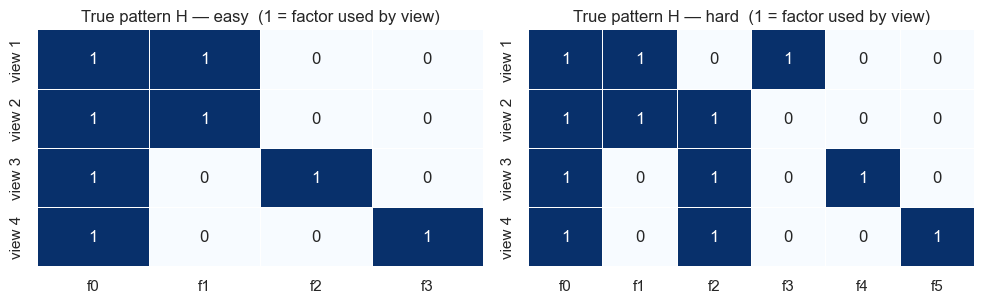

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (name, H) in zip(axes, [("easy", ex.LEVELS["easy"]["H"]), ("hard", ex.LEVELS["hard"]["H"])]):
    sns.heatmap(H, ax=ax, cmap="Blues", cbar=False, annot=True, linewidths=.5,
                xticklabels=[f"f{k}" for k in range(H.shape[1])],
                yticklabels=[f"view {m+1}" for m in range(H.shape[0])])
    ax.set_title(f"True pattern H — {name}  (1 = factor used by view)")
plt.tight_layout(); plt.show()

### Q3, the part that needs no fitting

How sure can a per-factor rate be, even with a perfectly observed pattern?

In [3]:
tab = ex.q3_counting_table()
tab.to_csv(os.path.join(RESULTS, "q3_counting.csv"), index=False)
tab

,M,n_patterns,pi_k_shared_mean,pi_k_shared_sd,pi_k_private_mean,pi_k_private_sd
0,2,3,0.750,0.194,0.500,0.224
1,3,7,0.800,0.163,0.400,0.200
2,4,15,0.833,0.141,0.333,0.178
3,6,63,0.875,0.110,0.250,0.144
4,8,255,0.900,0.090,0.200,0.121


Reading the table: at $M=2$ a shared factor's $\pi_k$ has posterior mean $0.75$ with sd $0.19$ and a private one
$0.50$ with sd $0.22$ — the two overlap almost completely. Per-factor rates only separate around $M\ge6$.

## Data inventory (what the real-data notebook can and cannot ask)

In [4]:
from sharedness.data import load_covid_views, load_four_view_cohort
cov = load_covid_views(top=150, cohort_mode="grouped")
fv = load_four_view_cohort(top=100)
inv = pd.DataFrame([
    dict(dataset="COVID", M=cov.M, N=cov.N, cohorts=len(np.unique(cov.labels)),
         features=[Y.shape[1] for Y in cov.Ys], views=cov.view_names, patterns=2**cov.M - 1),
    dict(dataset="four-view cohort table", M=fv.M, N=fv.N, cohorts=len(np.unique(fv.labels)),
         features=[Y.shape[1] for Y in fv.Ys], views=fv.view_names, patterns=2**fv.M - 1),
])
inv

,dataset,M,N,cohorts,features,views,patterns
0,COVID,2,378,3,"[150, 150]","[metabolomic, proteomic]",3
1,four-view cohort table,4,1038,6,"[25, 100, 53, 100]","[DNA, RNA, IF_dens, IF_inter]",15


**Caveats carried into notebook 03.** The four-view table is the IMMUCAN-style long table in the repo
root, restricted to the 1038 samples that have all four views (6 cohorts; SCCHN3 has no complete sample).
DNA is binary mutation calls (≈99.6 % zeros): only mutations present in ≥1 % of samples are kept (25 mutations; at 5 % only 3 would survive), and
they are fitted with a Gaussian likelihood, which is an approximation. The IMMUCAN loader in
`immucan_data/` needs a Mac drive path and is not used.